# 7005 · RQ2

先运行 `01_data_processing.ipynb`。分析读取同一个 `UPWORTHY_RUN_DIR` 下的 `upworthy_v2_scored.csv`（默认 `./7005_notebook_outputs/`）。独立运行每个 Notebook 时，请保持工作目录或该环境变量一致。

沿用[Part 3 Colab](https://colab.research.google.com/drive/1mowr780ZnA8N3k3HO-PcwEagjz0cEqlI) 的 M2、三套替代 NRC 评分检验和预测对比。模型保留实验随机截距。主表并列普通模型标准误与实验聚类结果，稳健性图以原版 M2 为对照，并显示普通 p < .05 的两套替代规则。三套完整记录保存在本次运行生成的 CSV。

## Load scored data and define the model design

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import norm

RUN_DIR=Path(os.environ.get("UPWORTHY_RUN_DIR","7005_notebook_outputs"))
SCORED_PATH=RUN_DIR/"upworthy_v2_scored.csv"
if not SCORED_PATH.is_file():
    raise FileNotFoundError(f"{SCORED_PATH}. Run 01_data_processing.ipynb first.")
df=pd.read_csv(SCORED_PATH,low_memory=False)
d=df.loc[df.groupby("clickability_test_id").id.transform("size").ge(2)].copy()
g,_=pd.factorize(d.clickability_test_id)
G=g.max()+1
y=d.clicks.to_numpy(float)
n=d.impressions.to_numpy(float)
assert d.id.is_unique and (np.bincount(g)>=2).all()
assert np.isfinite(y).all() and np.isfinite(n).all() and ((y>=0)&(y<=n)&(n>0)).all()
print(f"Analysis sample: {len(d):,} headlines in {G:,} experiments")
print(f"Clicks: {y.sum():,.0f} | Impressions: {n.sum():,.0f}")

def z(s):
    return (s-s.mean())/s.std(ddof=0)

def design(neg="neg_prop_nrc",pos="pos_prop_nrc",interaction=False):
    Z=pd.DataFrame({"z_neg":z(d[neg]),"z_pos":z(d[pos]),"z_fog":z(d.fog_score),
                    "z_len":z(d.n_words),"z_day":z(d.days_since_start)})
    if interaction:
        Z["z_neg:z_fog"]=Z.z_neg*Z.z_fog
    assert np.isfinite(Z).all().all()
    return np.column_stack([np.ones(len(d)),Z.to_numpy()]),["Intercept",*Z.columns],Z

Analysis sample: 43,931 headlines in 9,889 experiments
Clicks: 1,918,962 | Impressions: 164,050,024


## Colab model fitting · Laplace GLMM and cluster covariance

In [2]:
def _saturated(y,n):
    with np.errstate(divide="ignore",invalid="ignore"):
        a=np.where(y>0,y*np.log(y/n),0.)
        b=np.where(n-y>0,(n-y)*np.log((n-y)/n),0.)
    return a+b

def _inner(xb,sigma2,y,n,g,G,penalised=True,iters=100):
    """Newton iteration for experiment intercepts."""
    b=np.zeros(G)
    prec=1./sigma2 if penalised else 1e-10
    def Q(bb):
        eta=xb+bb[g]
        return np.bincount(g,y*eta-n*np.logaddexp(0,eta),G)-.5*prec*bb**2
    Qb=Q(b)
    for _ in range(iters):
        p=expit(xb+b[g])
        s=np.bincount(g,y-n*p,G)-b*prec
        h=np.bincount(g,n*p*(1-p),G)+prec
        step=s/h
        t=np.ones(G)
        for _ in range(40):
            Qn=Q(b+t*step)
            bad=Qn<Qb-1e-12*(1+np.abs(Qb))
            if not bad.any():
                break
            t[bad]*=.5
        b=b+t*step
        Qb=Q(b)
        if np.max(np.abs(t*step))<1e-11:
            break
    p=expit(xb+b[g])
    h=np.bincount(g,n*p*(1-p),G)+prec
    return b,p,h

def group_stats(theta,y,n,X,g,G,sat):
    """Per-experiment Laplace log likelihood and analytic score."""
    k=X.shape[1]
    beta,psi=theta[:-1],theta[-1]
    sigma2=np.exp(2*psi)
    xb=X@beta
    b,p,h=_inner(xb,sigma2,y,n,g,G)
    eta=xb+b[g]
    kap=n*p*(1-p)
    kap1=kap*(1-2*p)
    ll=y*eta-n*np.logaddexp(0,eta)-sat
    logL=np.bincount(g,ll,G)-b**2/(2*sigma2)-psi-.5*np.log(h)
    c=np.bincount(g,kap1,G)
    S=np.zeros((G,k+1))
    for j in range(k):
        xj=X[:,j]
        direct=np.bincount(g,(y-n*p)*xj,G)
        sk=np.bincount(g,kap*xj,G)
        sk1=np.bincount(g,kap1*xj,G)
        S[:,j]=direct-.5/h*(sk1-c*sk/h)
    S[:,k]=b**2/sigma2-1-.5/h*(-2/sigma2+c*2*b/(sigma2*h))
    return logL,S

def _f(theta,*a):
    return -group_stats(theta,*a)[0].sum()

def _g(theta,*a):
    return -group_stats(theta,*a)[1].sum(0)

def hess_from_grad(gfun,th,eps=1e-5):
    k=len(th)
    H=np.zeros((k,k))
    for i,e in enumerate(eps*np.eye(k)):
        H[:,i]=(gfun(th+e)-gfun(th-e))/(2*eps)
    return (H+H.T)/2

def newton(f,gfun,th,iters=60,tol=1e-9):
    for _ in range(iters):
        gr=gfun(th)
        H=hess_from_grad(gfun,th)
        w,V=np.linalg.eigh(H)
        w=np.maximum(w,1e-6*max(w.max(),1.))
        step=V@((V.T@gr)/w)
        t,f0=1.,f(th)
        while t>1e-8 and f(th-t*step)>f0+1e-12:
            t/=2
        th=th-t*step
        if np.max(np.abs(t*step))<tol:
            break
    return th

def fit_glmm(y,n,X,g,names):
    G=g.max()+1
    sat=_saturated(y,n)
    a=(y,n,X,g,G,sat)
    beta=np.zeros(X.shape[1])
    beta[0]=np.log(y.sum()/(n.sum()-y.sum()))
    for _ in range(8):
        p=expit(X@beta)
        w=n*p*(1-p)
        beta+=np.linalg.solve((X*w[:,None]).T@X,X.T@(y-n*p))
    th0=np.append(beta,np.log(.4))
    r=minimize(_f,th0,args=a,jac=_g,method="BFGS",options={"gtol":1e-3,"maxiter":300})
    th=newton(lambda t:_f(t,*a),lambda t:_g(t,*a),r.x)
    grad=_g(th,*a)
    H=hess_from_grad(lambda t:_g(t,*a),th)
    cov=np.linalg.inv(H)
    loglik,S=group_stats(th,*a)
    cov_rob=cov@(S.T@S)@cov
    se=np.sqrt(np.diag(cov))[:-1]
    se_rob=np.sqrt(np.diag(cov_rob))[:-1]
    _,pr,_=_inner(X@th[:-1],np.exp(2*th[-1]),y,n,g,G)
    disp=np.sum((y-n*pr)**2/(n*pr*(1-pr)))/(len(y)-len(th))
    coef=th[:-1]
    table=pd.DataFrame({"term":names,"coef":coef,"se":se,"p":2*norm.sf(abs(coef/se)),
                        "se_robust":se_rob,"p_robust":2*norm.sf(abs(coef/se_rob))})
    converged=np.max(np.abs(grad))<1e-3 and np.isfinite(se).all()
    if not converged:
        raise RuntimeError(f"GLMM did not converge: max gradient {np.max(np.abs(grad)):.6g}")
    return dict(table=table,theta=th,cov=cov,cov_rob=cov_rob,sigma=float(np.exp(th[-1])),
                loglik=float(loglik.sum()),dispersion=float(disp))

critical=norm.ppf(.975)

def fit_table(fit):
    table=fit["table"].copy()
    for prefix,s in [("ordinary","se"),("cluster","se_robust")]:
        table[f"{prefix}_low"]=table.coef-critical*table[s]
        table[f"{prefix}_high"]=table.coef+critical*table[s]
    return table

## Colab sensitivity test · Experiment fixed intercept

In [3]:
def fit_fixed_effects(y,n,X,g,names):
    G=g.max()+1
    Xs=X[:,1:]
    sat=_saturated(y,n)
    def prof(beta):
        xb=Xs@beta
        b,p,_=_inner(xb,1.,y,n,g,G,penalised=False)
        eta=xb+b[g]
        return -(y*eta-n*np.logaddexp(0,eta)-sat).sum(),p
    def f(beta):
        return prof(beta)[0]
    def grad(beta):
        return -(Xs.T@(y-n*prof(beta)[1]))
    th=newton(f,grad,np.zeros(Xs.shape[1]))
    np.testing.assert_allclose(grad(th),0,atol=1e-3)
    return th

def within_experiment(X,names,target):
    group_clicks=np.bincount(g,weights=y)
    group_trials=np.bincount(g,weights=n)
    eligible=((group_clicks>0)&(group_clicks<group_trials))[g]
    clicks,trials,design=y[eligible],n[eligible],X[eligible]
    group,keys=pd.factorize(g[eligible])
    count=len(keys)
    predictors=design[:,1:]
    slopes=fit_fixed_effects(clicks,trials,design,group,names)
    _,p,_=_inner(predictors@slopes,1.,clicks,trials,group,count,penalised=False)
    weight=trials*p*(1-p)
    weight_g=np.bincount(group,weights=weight)
    means=np.column_stack([np.bincount(group,weights=weight*col)/weight_g for col in predictors.T])
    centered=predictors-means[group]
    residual=clicks-trials*p
    np.testing.assert_allclose(centered.T@residual,0,atol=1e-3)
    bread=np.linalg.inv(centered.T@(weight[:,None]*centered))
    scores=np.column_stack([np.bincount(group,weights=residual*col) for col in centered.T])
    cov=bread@(scores.T@scores)@bread
    i=names[1:].index(target)
    b,se=slopes[i],np.sqrt(cov[i,i])
    return pd.DataFrame([dict(term=target,coef=b,se_cluster=se,p_cluster=2*norm.sf(abs(b/se)),
                              ci_low=b-critical*se,ci_high=b+critical*se,headlines=len(clicks),experiments=count)])

## Prediction and delta-method helpers from Part 3

In [4]:
def prediction_rows(names,negative_share,fog_z=0):
    neg=d.neg_prop_nrc
    share=np.atleast_1d(negative_share)
    rows=np.zeros((len(share),len(names)))
    rows[:,names.index("Intercept")]=1
    rows[:,names.index("z_neg")]=(share-neg.mean())/neg.std(ddof=0)
    rows[:,names.index("z_fog")]=fog_z
    if "z_neg:z_fog" in names:
        rows[:,names.index("z_neg:z_fog")]=rows[:,names.index("z_neg")]*fog_z
    return rows

def prediction(ax,fit,names,share,fog,color,label=None,covariance="cov_rob"):
    rows=prediction_rows(names,share,fog)
    eta=rows@fit["theta"][:-1]
    cov=fit[covariance][:-1,:-1]
    se=np.sqrt(np.einsum("ij,jk,ik->i",rows,cov,rows))
    ax.plot(100*share,100*expit(eta),color=color,label=label,lw=2)
    ax.fill_between(100*share,100*expit(eta-critical*se),100*expit(eta+critical*se),color=color,alpha=.15)

def contrast_row(label,fit,rows,weights,covariance="cov_rob"):
    prob=expit(rows@fit["theta"][:-1])
    gradient=weights@((prob*(1-prob))[:,None]*rows)
    cov=fit[covariance][:-1,:-1]
    estimate=10_000*(weights@prob)
    se=10_000*np.sqrt(gradient@cov@gradient)
    return dict(contrast=label,estimate=estimate,ci_low=estimate-critical*se,
                ci_high=estimate+critical*se,p=2*norm.sf(abs(estimate/se)))

def finish_plot(fig,ax,filename):
    ax.spines[["top","right"]].set_visible(False)
    fig.tight_layout(rect=(0,.075,1,1) if fig.texts else None)
    fig.savefig(RUN_DIR/filename,dpi=180,bbox_inches="tight")
    plt.show()

def plot_intervals(table,title,xlabel,filename):
    fig,ax=plt.subplots(figsize=(8.5,1.6+.55*len(table)))
    estimates=table.estimate.to_numpy()
    ax.axvline(0,color="#777777",lw=1)
    ax.errorbar(estimates,np.arange(len(table)),xerr=[estimates-table.ci_low,table.ci_high-estimates],
                fmt="o",color="#285b8e",capsize=4)
    ax.set(yticks=np.arange(len(table)),yticklabels=table.contrast,title=title,xlabel=xlabel)
    ax.invert_yaxis()
    finish_plot(fig,ax,filename)

## M2 · Negative-word share × Gunning Fog

In [5]:
X2,names2,Z2=design(interaction=True)
m2=fit_glmm(y,n,X2,g,names2)
m2_table=fit_table(m2)
m2_table.to_csv(RUN_DIR/"RQ2_M2.csv",index=False)
display(m2_table.round(6))
print(f"Pearson dispersion: {m2['dispersion']:.3f}")

Pearson dispersion: 3.124


,term,coef,se,p,se_robust,p_robust,ordinary_low,ordinary_high,cluster_low,cluster_high
0,Intercept,-4.592049,0.006153,0.000000,0.006152,0.000000,-4.604109,-4.579990,-4.604108,-4.579991
1,z_neg,0.007964,0.001090,0.000000,0.002612,0.002298,0.005827,0.010100,0.002844,0.013083
2,z_pos,-0.010150,0.001081,0.000000,0.002620,0.000107,-0.012269,-0.008030,-0.015285,-0.005014
3,z_fog,-0.002340,0.001082,0.030520,0.002651,0.377362,-0.004460,-0.000220,-0.007536,0.002856
4,z_len,0.039447,0.001104,0.000000,0.002670,0.000000,0.037284,0.041610,0.034214,0.044679
5,z_day,-0.219555,0.005815,0.000000,0.005748,0.000000,-0.230953,-0.208157,-0.230822,-0.208289
6,z_neg:z_fog,-0.001975,0.000833,0.017708,0.001951,0.311371,-0.003607,-0.000343,-0.005799,0.001849


## Sensitivity check · Within-experiment comparisons

In [6]:
rq2_within=within_experiment(X2,names2,"z_neg:z_fog")
rq2_within.to_csv(RUN_DIR/"RQ2_within_experiment.csv",index=False)
display(rq2_within.round(6))

,term,coef,se_cluster,p_cluster,ci_low,ci_high,headlines,experiments
0,z_neg:z_fog,-0.002017,0.001967,0.305115,-0.005873,0.001838,43929,9888


## Sensitivity checks · Three alternative NRC rules

In [7]:
alternatives=[
    ("Alternative negation","_alt"),
    ("Exact dictionary forms","_exact"),
    ("Four ambiguous words excluded","_core"),
]
scoring_results=[]
for label,suffix in alternatives:
    X_alt,names_alt,_=design("neg_prop_nrc"+suffix,"pos_prop_nrc"+suffix,interaction=True)
    alternative=fit_glmm(y,n,X_alt,g,names_alt)
    row=fit_table(alternative).loc[lambda t:t.term.eq("z_neg:z_fog")].assign(rule=label)
    scoring_results.append(row)
sensitivity=pd.concat(scoring_results,ignore_index=True)
sensitivity.to_csv(RUN_DIR/"RQ2_all_alternative_scoring.csv",index=False)
print(f"{sensitivity.p.lt(.05).sum()} of {len(sensitivity)} alternatives had ordinary p < .05.")

2 of 3 alternatives had ordinary p < .05.


## Figure 05 · Original M2 and two alternative scoring rules

第一行是原版 M2。另两行展示三套已测试规则中按普通模型标准误显著的两套。三行全部使用普通模型的 95% 置信区间。完整替代规则结果见导出的 CSV。

<ipython-input-1-3a5a0d8a02a8>:48: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,rule,coef,ordinary_low,ordinary_high,p
0,Original M2,-0.001975,-0.003607,-0.000343,0.017708
1,Exact dictionary forms,-0.002153,-0.003797,-0.000510,0.010232
2,Four ambiguous words excluded,-0.001874,-0.003501,-0.000247,0.023972


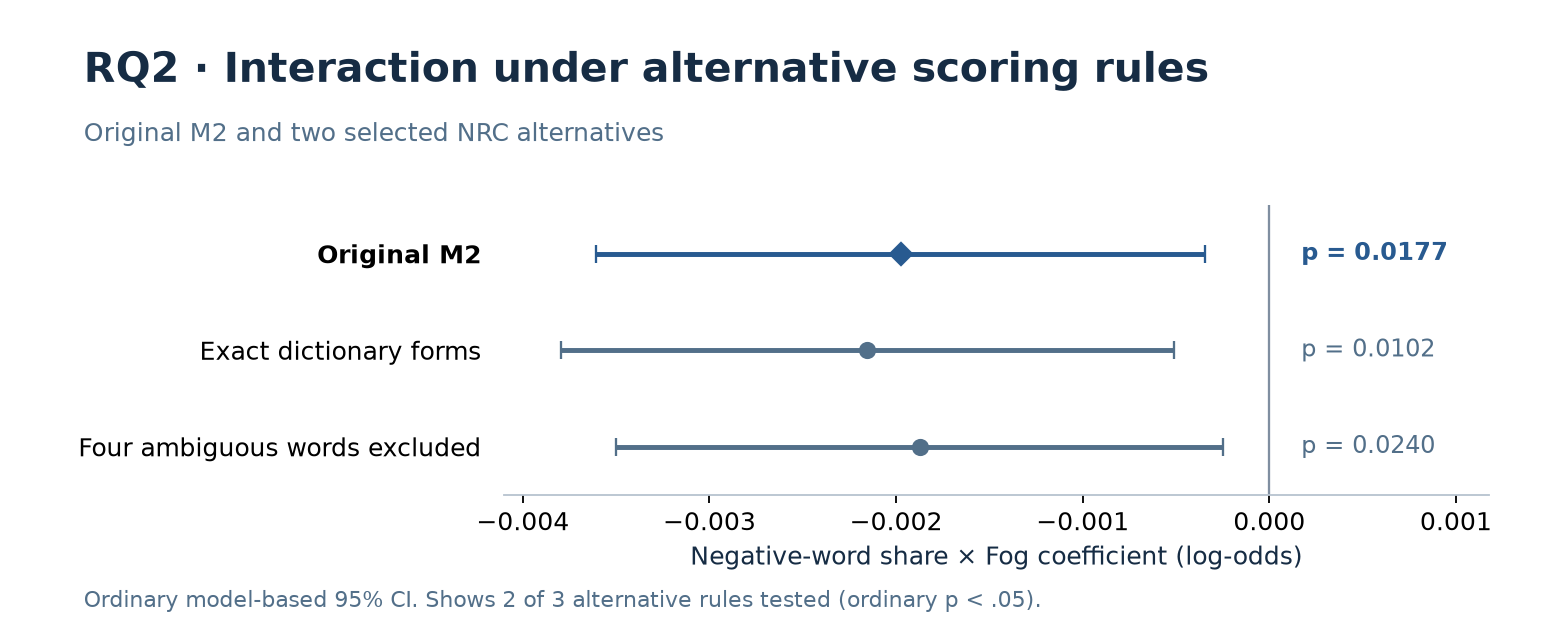

In [8]:
from matplotlib.ticker import MultipleLocator

# The baseline is separate from the three alternative NRC rules tested.
baseline = m2_table.loc[m2_table.term.eq("z_neg:z_fog")].assign(rule="Original M2")
shown_alternatives = sensitivity.loc[sensitivity.p.lt(.05)]
forest = pd.concat([baseline, shown_alternatives], ignore_index=True)
display(forest[["rule", "coef", "ordinary_low", "ordinary_high", "p"]].round(6))

ink, blue, muted = "#162c44", "#285a90", "#526f89"
with plt.rc_context({"font.size": 11, "axes.labelcolor": ink, "text.color": ink}):
    fig, ax = plt.subplots(figsize=(9.4, 3.9))
    fig.subplots_adjust(left=.325, right=.96, top=.68, bottom=.23)
    fig.text(.054, .872, "RQ2 · Interaction under alternative scoring rules",
             fontsize=18, weight="bold")
    fig.text(.054, .78, "Original M2 and two selected NRC alternatives",
             fontsize=11, color=muted)

    low = min(0, forest.ordinary_low.min())
    high = max(0, forest.ordinary_high.max())
    width = high - low
    p_x = high + .045 * width
    ax.axvline(0, color="#7f8ea0", lw=1, zorder=0)

    for i, row in enumerate(forest.itertuples(index=False)):
        color = blue if i == 0 else muted
        ax.errorbar(row.coef, i,
                    xerr=[[row.coef-row.ordinary_low], [row.ordinary_high-row.coef]],
                    fmt="D" if i == 0 else "o", color=color,
                    capsize=4, markersize=6.5, elinewidth=2.15)
        ax.text(p_x, i, f"p = {row.p:.4f}", va="center", ha="left",
                color=color, fontsize=10.5, weight="bold" if i == 0 else "normal")
    ax.set(yticks=range(len(forest)), yticklabels=forest.rule,
           xlim=(low-.08*width, high+.31*width),
           ylim=(len(forest)-.5,-.5),
           xlabel="Negative-word share × Fog coefficient (log-odds)")
    ax.get_yticklabels()[0].set_weight("bold")
    ax.tick_params(axis="y", length=0, pad=10)
    ax.xaxis.set_major_locator(MultipleLocator(.001))
    ax.yaxis.grid(False)
    for edge in ("top", "right", "left"):
        ax.spines[edge].set_visible(False)
    ax.spines["bottom"].set_color("#b8c4d0")
    fig.text(.054, .056,
             f"Ordinary model-based 95% CI. Shows {len(shown_alternatives)} of {len(sensitivity)} "
             "alternative rules tested (ordinary p < .05).",
             color=muted, fontsize=9.5)
    fig.savefig(RUN_DIR / "05_rq2_scoring_sensitivity.png", dpi=165, facecolor="white")
    plt.show()

## Figure 03 · Predicted CTR at three Fog levels

PPT 主图。沿用第一个 Colab 的 M2 和三个 Fog 参考值。横轴为实际负面词占比，竖虚线标出 5.93%（一个样本标准差）。三条线显示预测值。

<ipython-input-1-93c1828203db>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


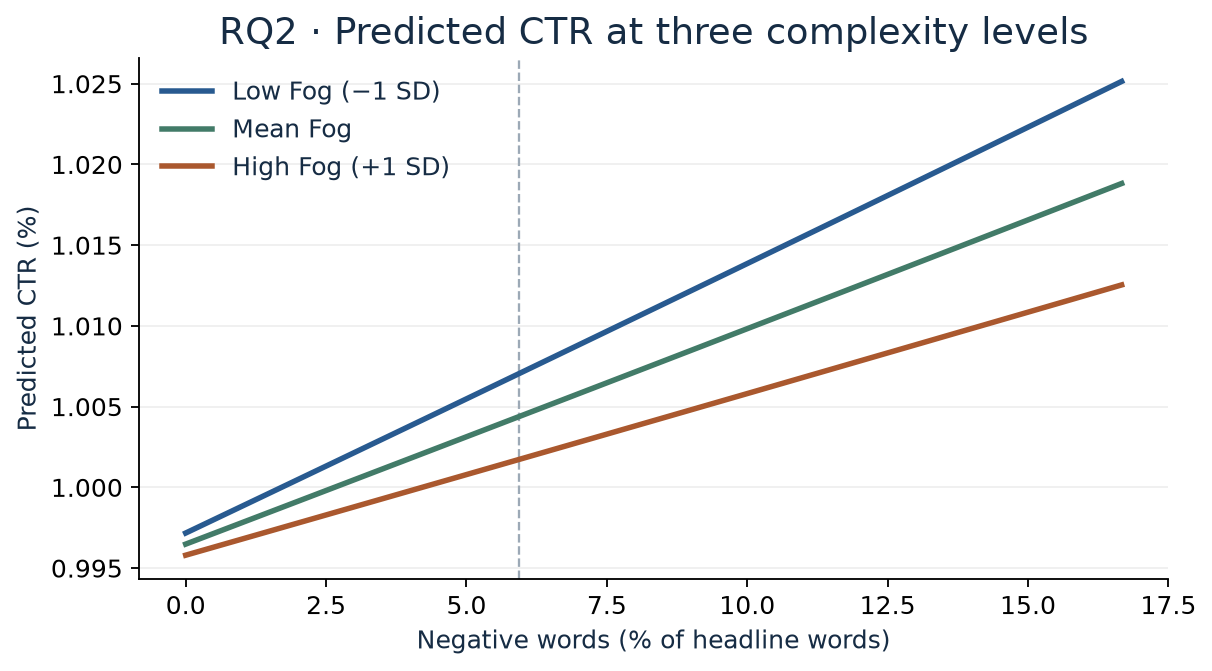

In [9]:
neg = d.neg_prop_nrc
neg_sd = neg.std(ddof=0)
share = np.linspace(0, neg.quantile(.95), 100)
# Keep the same Fog levels and labels for the contrast table below.
levels = [(-1, "#336ba7", "Low complexity (−1 SD)"),
          (0, "#54705c", "Mean complexity"),
          (1, "#aa582e", "High complexity (+1 SD)")]
plot_levels = [(-1, "#285a90", "Low Fog (−1 SD)"),
               (0, "#427b68", "Mean Fog"),
               (1, "#aa582e", "High Fog (+1 SD)")]

with plt.rc_context({"font.size": 11, "axes.titlesize": 16, "axes.labelcolor": "#162c44",
                     "text.color": "#162c44", "axes.spines.right": False,
                     "axes.spines.top": False}):
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for fog, color, label in plot_levels:
        rows = prediction_rows(names2, share, fog)
        predicted_ctr = expit(rows @ m2["theta"][:-1])
        ax.plot(100 * share, 100 * predicted_ctr, color=color, label=label, lw=2.4)

    ax.axvline(100 * neg_sd, color="#9ca9b6", lw=1, ls="--", zorder=0)
    ax.set(title="RQ2 · Predicted CTR at three complexity levels",
           xlabel="Negative words (% of headline words)", ylabel="Predicted CTR (%)")
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=.2)
    fig.tight_layout()
    fig.savefig(RUN_DIR / "03_rq2_interaction.png", dpi=165,
                bbox_inches="tight", facecolor="white")
    plt.show()

## Supplementary figure 04 · Click gains and the low-minus-high difference

<ipython-input-1-a1fc9af5c176>:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,contrast,estimate,ci_low,ci_high,p,inference
0,Low complexity (−1 SD),0.9860,0.7060,1.2659,0.0000,Ordinary model-based
1,Mean complexity,0.7887,0.5775,1.0000,0.0000,Ordinary model-based
2,High complexity (+1 SD),0.5922,0.3414,0.8429,0.0000,Ordinary model-based
3,Low minus high,0.3938,0.0716,0.7160,0.0166,Ordinary model-based
4,Low complexity (−1 SD),0.9860,0.3310,1.6410,0.0032,Experiment-clustered
5,Mean complexity,0.7887,0.2829,1.2946,0.0022,Experiment-clustered
6,High complexity (+1 SD),0.5922,-0.0145,1.1988,0.0557,Experiment-clustered
7,Low minus high,0.3938,-0.3613,1.1489,0.3067,Experiment-clustered


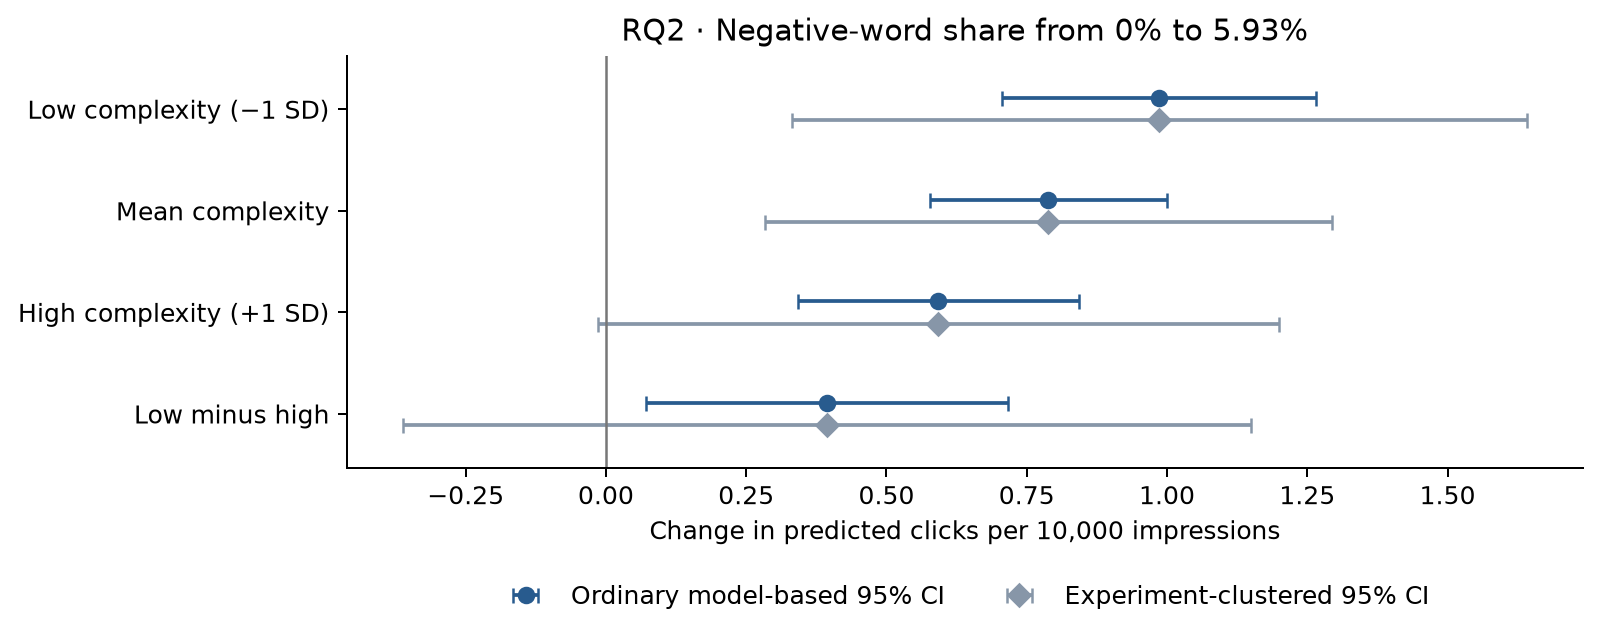

In [10]:
rows={fog:prediction_rows(names2,[0,neg_sd],fog) for fog,_,_ in levels}
difference_rows=np.vstack([rows[-1],rows[1]])
comparison_rows=[]
for cov,label in [("cov","Ordinary model-based"),("cov_rob","Experiment-clustered")]:
    for fog,_,name in levels:
        comparison_rows.append(dict(contrast_row(name,m2,rows[fog],np.array([-1,1]),cov),inference=label))
    comparison_rows.append(dict(contrast_row("Low minus high",m2,difference_rows,
                                             np.array([-1,1,1,-1]),cov),inference=label))
click_contrasts=pd.DataFrame(comparison_rows)
click_contrasts.to_csv(RUN_DIR/"RQ2_click_contrasts.csv",index=False)
display(click_contrasts.round(4))
fig,ax=plt.subplots(figsize=(9,3.8))
for offset,inference,color,marker in [(-.11,"Ordinary model-based","#285b8e","o"),
                                      (.11,"Experiment-clustered","#8796a8","D")]:
    subset=click_contrasts[click_contrasts.inference.eq(inference)]
    positions=np.arange(len(subset))
    ax.errorbar(subset.estimate,positions+offset,
        xerr=[subset.estimate-subset.ci_low,subset.ci_high-subset.estimate],
        fmt=marker,color=color,capsize=3,label=inference+" 95% CI")
ax.axvline(0,color="#777777",lw=1)
ax.set(yticks=positions,yticklabels=subset.contrast,
       title=f"RQ2 · Negative-word share from 0% to {neg_sd:.2%}",
       xlabel="Change in predicted clicks per 10,000 impressions")
ax.invert_yaxis()
ax.margins(y=.13)
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.23),ncol=2,frameon=False)
finish_plot(fig,ax,"04_rq2_click_contrasts.png")

## Supplementary figure 09 · Four predicted CTR values and the difference in gains

补充图。四个点来自同一个 M2，底部区间使用普通模型协方差。PPT 主图见图 03。

<ipython-input-1-c36bdc3cd9c6>:70: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


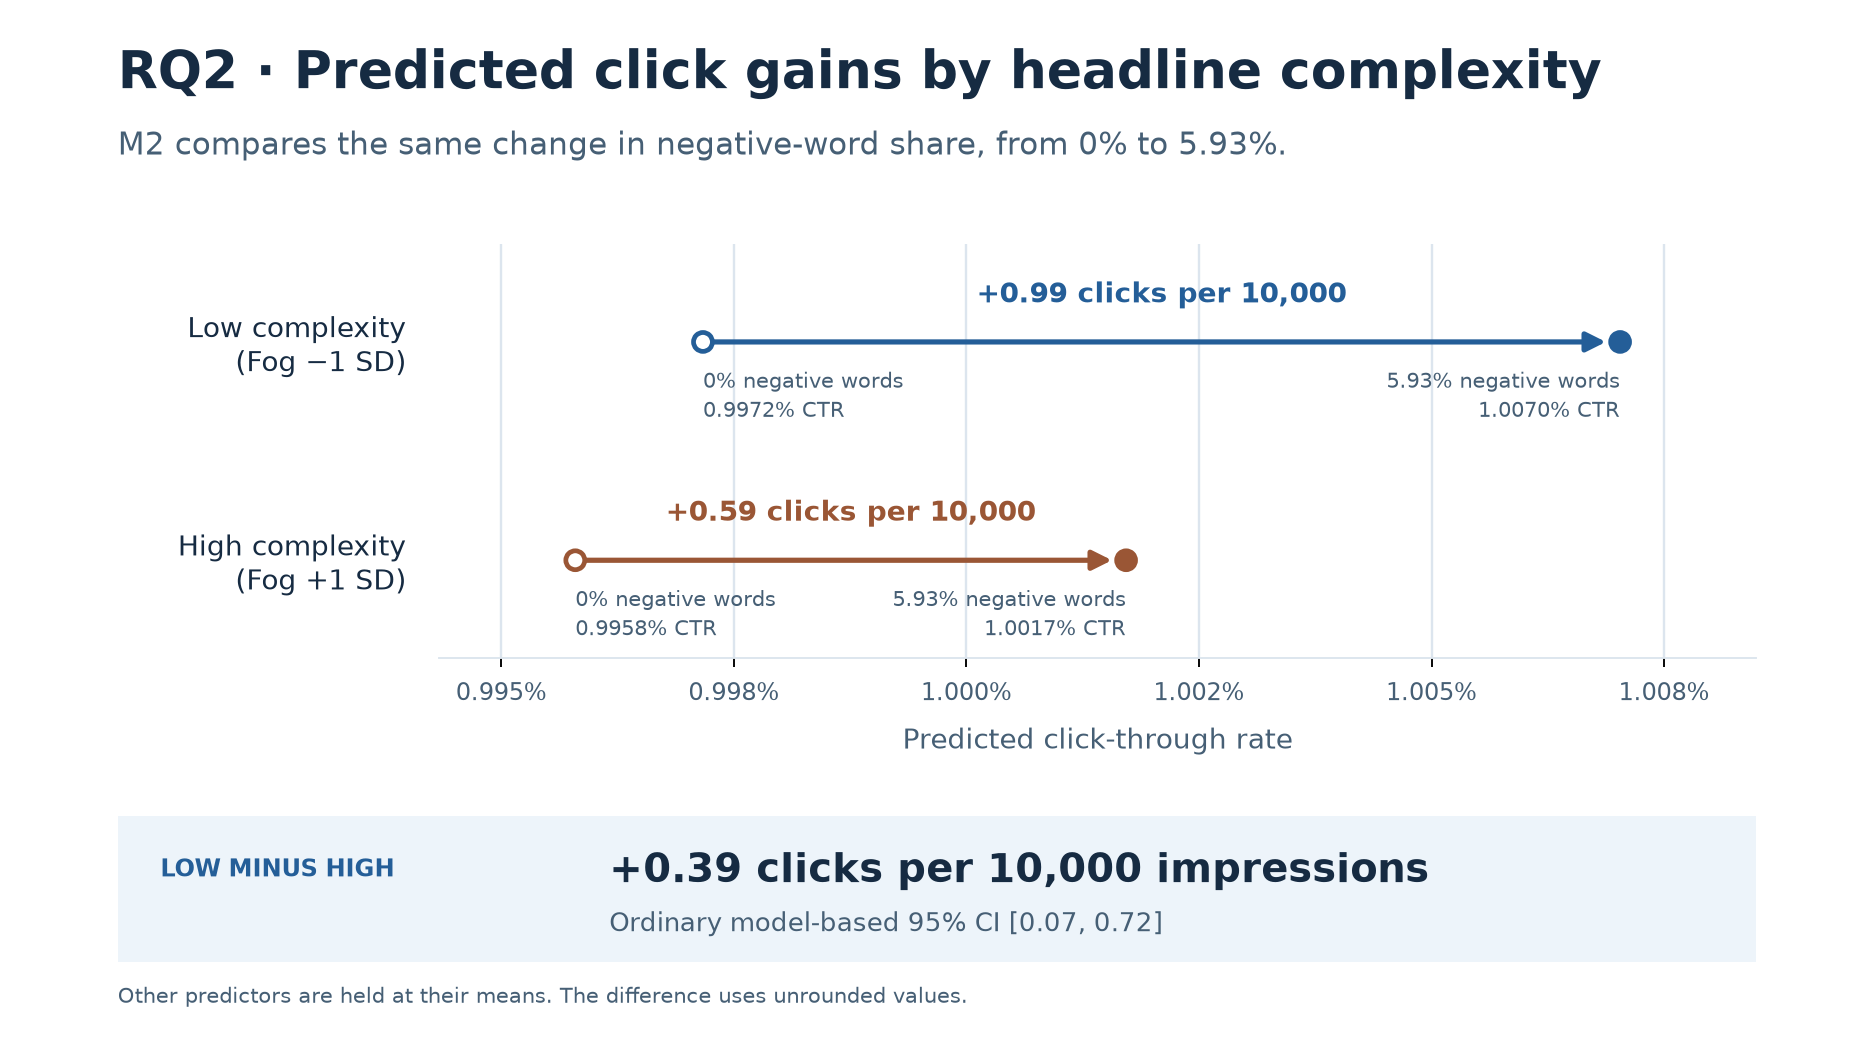

In [11]:
from matplotlib.ticker import FuncFormatter

# Use the fitted M2 and the ordinary model-based contrast already computed above.
sd = neg_sd
ordinary = click_contrasts.loc[
    click_contrasts.inference.eq("Ordinary model-based")
].set_index("contrast")
points = {
    fog: expit(prediction_rows(names2, [0, sd], fog) @ m2["theta"][:-1])
    for fog in (-1, 1)
}
diff = ordinary.loc["Low minus high"]
np.testing.assert_allclose(
    (np.diff(points[-1])[0] - np.diff(points[1])[0]) * 10_000,
    diff.estimate,
    atol=1e-7,
)

ink="#162b42"
muted="#465f75"
low="#245e98"
high="#9a5635"
grid="#dce5ee"
fig=plt.figure(figsize=(11,6.1),dpi=170,facecolor="white")
fig.text(.063,.915,"RQ2 · Predicted click gains by headline complexity",fontsize=22,weight="bold",color=ink)
fig.text(.063,.851,f"M2 compares the same change in negative-word share, from 0% to {sd:.2%}.",fontsize=13,color=muted)
ax=fig.add_axes([.235,.365,.704,.40])
ax.set_ylim(-.45,1.45)
bounds = 100 * np.concatenate(list(points.values()))
padding = (bounds.max() - bounds.min()) * .13
ax.set_xlim(bounds.min() - padding, bounds.max() + padding)
ax.xaxis.set_major_locator(plt.MaxNLocator(6))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x,_: f"{x:.3f}%"))
ax.set_yticks([1,0],["Low complexity\n(Fog −1 SD)","High complexity\n(Fog +1 SD)"])
ax.tick_params(axis="y",length=0,pad=14,labelsize=12,labelcolor=ink)
ax.tick_params(axis="x",length=4,pad=6,labelsize=10,labelcolor=muted)
ax.set_xlabel("Predicted click-through rate",fontsize=12,color=muted,labelpad=9)
ax.grid(axis="x",color=grid,lw=1)
ax.set_axisbelow(True)
for s in ("left","right","top"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(grid)
for f, y, color in [(-1,1,low),(1,0,high)]:
    x0,x1=100*points[f]
    ax.annotate("",xy=(x1,y),xytext=(x0,y),
                arrowprops={"arrowstyle":"-|>","mutation_scale":17,"lw":2.2,
                            "color":color,"shrinkA":4,"shrinkB":6})
    ax.scatter([x0,x1],[y,y],s=64,edgecolors=color,facecolors=["white",color],linewidths=2,zorder=4)
    for x, title, align, xoff in [(x0,"0% negative words","left",0),(x1,f"{sd:.2%} negative words","right",0)]:
        ax.annotate(f"{title}\n{x:.4f}% CTR",xy=(x,y),xytext=(xoff,-11),textcoords="offset points",
                    color=muted,ha=align,va="top",fontsize=9,linespacing=1.3)
    ax.text((x0+x1)/2,y+.15,f"+{(x1-x0)*100:.2f} clicks per 10,000",
            ha="center",va="bottom",fontsize=12,color=color,weight="bold")

box=fig.add_axes([.063,.072,.876,.141])
box.set_facecolor("#edf4fa")
box.set_xticks([])
box.set_yticks([])
for edge in box.spines.values():
    edge.set_visible(False)
box.text(.026,.63,"LOW MINUS HIGH",transform=box.transAxes,color=low,fontsize=10,weight="bold",va="center")
box.text(.30,.62,f"+{diff.estimate:.2f} clicks per 10,000 impressions",transform=box.transAxes,
         color=ink,fontsize=17,weight="bold",va="center")
box.text(.30,.26,f"Ordinary model-based 95% CI [{diff.ci_low:.2f}, {diff.ci_high:.2f}]",
         transform=box.transAxes,color=muted,fontsize=11,va="center")
fig.text(.063,.033,"Other predictors are held at their means. The difference uses unrounded values.",
         color=muted,fontsize=9)

fig.savefig(RUN_DIR / "09_rq2_four_point_comparison.png", dpi=170, facecolor="white")
plt.show()

## Figure · Observed negativity distribution by Fog band

<ipython-input-1-a1fc9af5c176>:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,headlines,zero_share,median_positive,p95
Fog band,,,,
Low Fog,16118,0.5046,0.0714,0.1538
Middle Fog,14986,0.4828,0.0714,0.1538
High Fog,12827,0.4489,0.0769,0.1765


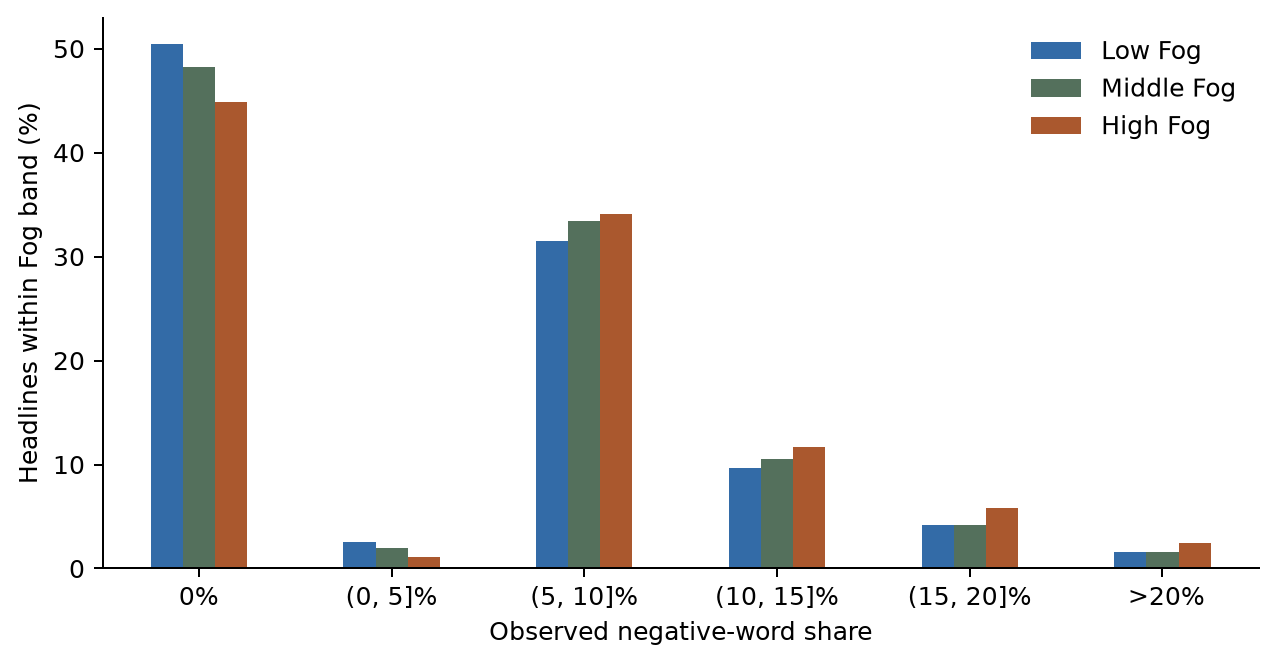

In [12]:
fog_band=pd.cut(z(d.fog_score),[-np.inf,-.5,.5,np.inf],labels=["Low Fog","Middle Fog","High Fog"])
support=pd.DataFrame({"Fog band":fog_band,"Negative share":d.neg_prop_nrc})
summary_support=support.groupby("Fog band",observed=True)["Negative share"].agg(
    headlines="size",zero_share=lambda s:s.eq(0).mean(),
    median_positive=lambda s:s[s.gt(0)].median(),p95=lambda s:s.quantile(.95))
display(summary_support.round(4))
summary_support.to_csv(RUN_DIR/"RQ2_observed_distribution.csv")
edges=[0,5,10,15,20,np.inf]
distribution=[]
for label,group in support.groupby("Fog band",observed=True):
    share_pct=100*group["Negative share"]
    positive_bins=pd.cut(share_pct[share_pct.gt(0)],bins=edges).value_counts(sort=False)
    distribution.append([share_pct.eq(0).mean(),*(positive_bins/len(group))])
bar_data=pd.DataFrame(np.array(distribution).T*100,columns=summary_support.index,
                      index=["0%","(0, 5]%","(5, 10]%","(10, 15]%","(15, 20]%"," >20%"])
fig,ax=plt.subplots(figsize=(7.2,3.8))
bar_data.plot.bar(ax=ax,color=["#336ba7","#54705c","#aa582e"],rot=0)
ax.set(xlabel="Observed negative-word share",ylabel="Headlines within Fog band (%)")
ax.legend(frameon=False)
finish_plot(fig,ax,"06_rq2_observed_distribution.png")